# 01 · Measure one image
[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/parallaxmetrology/visual-thinking-lens/blob/main/notebooks/01_measure_one_image.ipynb)

The kernel turns an image into a handful of numbers describing **where structural mass sits and how it is organized**. It never looks at what the image depicts.

`image → grayscale → Sobel gradient → mass mask (P85–P97 band) → kernel vector`

In [1]:
# Works locally (pip install -e .) or in Colab.
try:
    import vtl
except ImportError:
    %pip install -q git+https://github.com/parallaxmetrology/visual-thinking-lens
    import vtl
from pathlib import Path
IMAGES = Path("../examples/images") if Path("../examples/images").exists() else None
if IMAGES is None:  # Colab: fetch the sample images
    !git clone -q --depth 1 https://github.com/parallaxmetrology/visual-thinking-lens /content/vtl-repo
    IMAGES = Path("/content/vtl-repo/examples/images")
print("vtl", vtl.__version__, "| images:", IMAGES)

vtl 0.1.0 | images: ../examples/images


In [2]:
k, fields = vtl.measure(IMAGES / "frog.jpg", return_fields=True)
{key: round(k[key], 4) for key in vtl.KERNEL_KEYS}

{'delta_x': 0.0085,
 'delta_y': -0.1869,
 'r_v': 0.7304,
 'rho_r': 14.5551,
 'mu': 0.3829,
 'x_p': 0.3892,
 'theta': 0.0003,
 'd_s': 0.0016,
 'sdi': 0.1843}

| key | name | reads |
|---|---|---|
| `delta_x`, `delta_y` | placement | where the mass centroid sits (−0.5…0.5; negative `delta_y` = upper frame) |
| `r_v` | void ratio | share of the frame below an absolute gradient threshold |
| `rho_r` | packing density | mass area ÷ convex hull area (×100) |
| `mu` | cohesion | one dominant body (→1) vs many equal fragments (→0) |
| `x_p` | peripheral pull | share of gradient energy in the outer 15% band |
| `theta` | orientation stability | one dominant direction (→1) vs omnidirectional (→0) |
| `d_s` | structural thickness | mean stroke width along the skeleton |
| `sdi` | spatial dispersion | how far mass spreads from its own centroid |

### What did it measure?
Left: mass (gold) on the luminance, frame center (sage cross) and mass centroid (red). Middle: gradient field. Right: the mask.

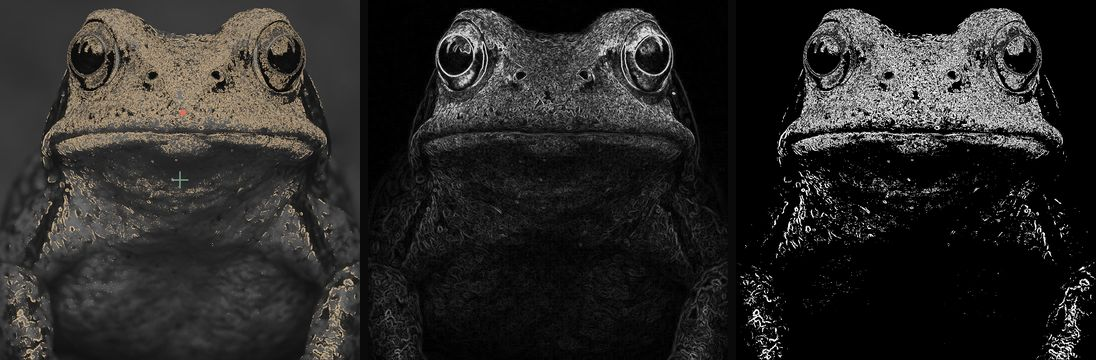

In [3]:
import io
from IPython.display import Image as Show
from vtl.viz import kernel_overlay
buf = io.BytesIO(); kernel_overlay(fields, k, panel=360).save(buf, "JPEG", quality=80)
Show(buf.getvalue())

### Mask QA
QA describes the field; it doesn't judge it. `TEXTURE_FIELD` / "island soup" is normal for textured or ornamental images.

In [4]:
vtl.mask_qa(fields.mass_mask)

{'mass_fraction': 0.11938391791449653,
 'n_components': 15135,
 'largest_component_fraction': 0.36527114058694465,
 'mask_sha256': '61601d69e725a93507cc121f7ecfbcde7e38370d825855040e1e62856be91e3a',
 'mask_status': 'WARN',
 'mask_reasons': 'extremely high component count (likely texture-driven)',
 'mask_mode': 'REGION_FIELD',
 'structure_regime': 'region'}

### One number means little
A centered composition is a valid choice. The kernel becomes diagnostic across **many** images: a maker that lands on the same coordinates whatever you ask for has a default. That's notebook 02.